In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [4]:
data = pd.read_csv('/home/entr0py/Python/ai-ml-log/ML_ZoomCamp/car_price_predictor(session 2)/data.csv')


In [5]:
data.columns = data.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')
data.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [6]:
string = data.dtypes[data.dtypes =='string'].index
string

for col in string:
    data[col] = data[col].str.strip().str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')


In [7]:
data.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_required,335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_required,300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_required,300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_required,230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_required,230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [8]:
for col in data.columns:
    print(col)
    print(data[col].unique()[:5])
    print(data[col].nunique())
    print()

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium_unleaded_required',             'regular_unleaded',
 'premium_unleaded_recommended',       'flex-fuel_unleaded/e85',
                       'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-performance'

In [9]:
import matplotlib.pyplot as plt
import seaborn as sbs

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

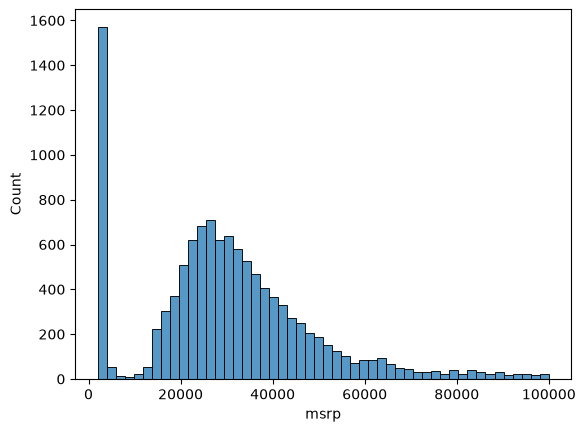

In [10]:
sbs.histplot(data.msrp[data.msrp < 100000], bins = 50)

<Axes: xlabel='msrp', ylabel='Count'>

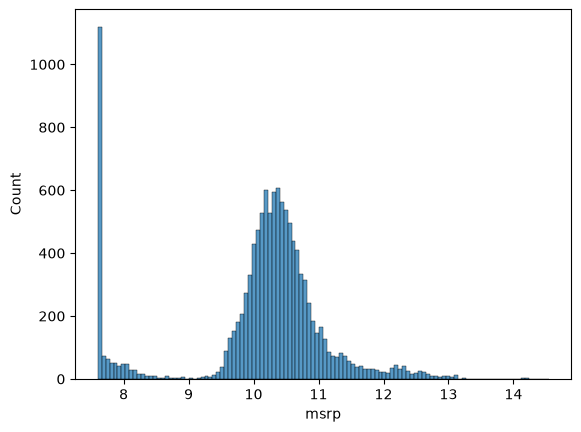

In [11]:
price_log = np.log1p(data.msrp)
sbs.histplot(price_log)

In [12]:
n = int(len(data))
n_val = int(len(data) * 0.2)
n_test = int(len(data) * 0.2)
n_train= n - (n_val + n_test)

print(n_val +n_test+n_train , n)

11914 11914


In [13]:
df_Val = data.iloc[:n_val]
df_test = data.iloc[n_val:n_val+ n_test]
df_train = data.iloc[n_val + n_test:]

In [14]:
np.random.seed(2)
idx = np.arange(n)
np.random.shuffle(idx)

In [15]:
df_train = data.iloc[idx[:n_train]]
df_val = data.iloc[idx[n_train:n_train+n_val]]
df_test = data.iloc[idx[n_train+n_val:]]


In [16]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [17]:
print(len(df_train), len(df_test) ,len(df_val) )

7150 2382 2382


In [18]:
y_train = np.log1p(df_train.msrp.values)
y_test = np.log1p(df_test.msrp.values)
y_val = np.log1p(df_val.msrp.values)

In [19]:
del df_train['msrp']
del df_test['msrp']
del df_val['msrp']

# Linear_Regression


In [20]:
df_train.iloc[10]

make                               rolls-royce
model                   phantom_drophead_coupe
year                                      2015
engine_fuel_type     premium_unleaded_required
engine_hp                                453.0
engine_cylinders                          12.0
transmission_type                    automatic
driven_wheels                 rear_wheel_drive
number_of_doors                            2.0
market_category      exotic,luxury,performance
vehicle_size                             large
vehicle_style                      convertible
highway_mpg                                 19
city_mpg                                    11
popularity                                  86
Name: 10, dtype: object

In [21]:
xi = [453 , 11 , 86]
demo_w0 = 7.12
demo_w = [0.01 , 0.02 , 0.004]
def linear_regression(xi):
    l = len(xi)
    pred = demo_w0

    for j in range(l):
        pred = pred+ demo_w[j]*xi[j]
    return pred

print(linear_regression(xi))
        

12.214


In [22]:
demo_w_full = [demo_w0] + demo_w
demo_xi_full = [1] + xi
np.dot(demo_xi_full, demo_w_full)

np.float64(12.214)

In [23]:
xi = np.array([453 , 11 , 86])
demo_w0 = 7.12
demo_w = np.array([0.01 , 0.02 , 0.004])

pred = demo_w0 + np.dot(xi , demo_w)
print(pred)

12.214


In [24]:
x1 = [12,34,305]
x2 = [11,64,260]
x3 = [19,24,410]

X = np.array([x1,x2,x3])
X_full = np.column_stack([np.ones(X.shape[0]), X])

X_full.dot(demo_w_full)


array([9.14, 9.55, 9.43])

In [25]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [26]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
dtype: object

In [27]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [28]:
base = ['year' , 'engine_cylinders' , 'highway_mpg' , 'city_mpg' , 'popularity']
df_train[base]

,year,engine_cylinders,highway_mpg,city_mpg,popularity
0,2008,4.0,33,24,1385
1,2012,4.0,32,25,2031
2,2016,4.0,37,28,640
3,1991,4.0,18,16,873
4,2017,8.0,21,15,5657
...,...,...,...,...,...
7145,2015,6.0,31,20,3916
7146,2015,4.0,30,24,873
7147,2015,6.0,22,17,549
7148,2014,12.0,21,13,86


In [29]:
# X_train = df_train[base].isnull().sum()
# X_train

In [30]:
X_train = df_train[base].fillna(0).values

In [31]:
w0 , w = train_linear_regression(X_train , y_train)

In [32]:
# Re-train immediately so stale demo weights can never be used here.
w0, w = train_linear_regression(X_train, y_train)
assert w.shape[0] == X_train.shape[1]
y_pred = w0 + X_train.dot(w)
y_pred

array([ 9.45884644,  9.89123962, 10.44331812, ..., 10.78502433,
       12.19857679, 10.50775664], shape=(7150,))

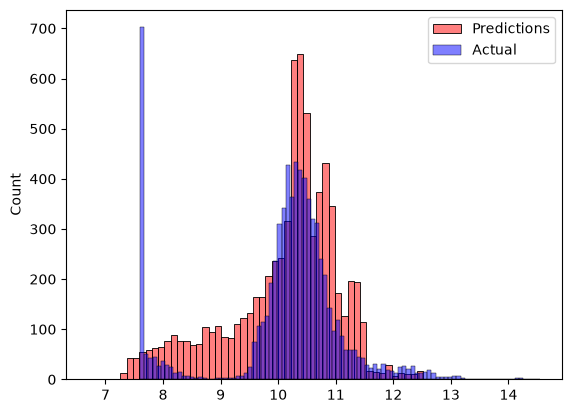

In [33]:
sns.histplot(y_pred, color='red', alpha=0.5, label='Predictions')
sns.histplot(y_train, color='blue', alpha=0.5, label='Actual')
plt.legend()
plt.show()

In [42]:
def rmse(y , y_pred):
    se = ((y - y_pred)**2)
    mse = se.mean()
    return np.sqrt(mse)



In [35]:
rmse(y_train , y_pred)

np.float64(0.5605995909466283)

# Validating the dataset


In [37]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [45]:
X_train = prepare_X(df_train)
w0 , w = train_linear_regression(X_train , y_train)


X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)

In [46]:
rmse(y_val , y_pred)

np.float64(0.5499340462173663)

# Adding new feature